# Práctica 2

**Mateo Zariquiey Pérez     100522396**

**Héctor Fuertes Muñoz      100522401**


## 1. Introducción y objetivos

En esta práctica se trata un problema de **aprendizaje no supervisado**, cuyo objetivo es identificar los posibles patrones y agrupaciones presentes un dataset  sin disponer de etiquetas previas. A diferencia de un aprendizaje supervisado, en este caso no se parte de una variable objetivo conocida, sino que se explora la estructura interna de los datos a partir de las relaciones y similitudes que presentan entre sus atributos.

Por lo tanto, en esta práctica se trabajará con un dataset formado por las características de distintas estrellas, que será la base utilizada para aplicar las técnicas de **clustering**. El análisis se dividirá en:
+ Transformación de los datos.
+ Reducción de dimensionalidad (PCA).
+ Aplicación de los distintos algoritmos de clustering.

También se estudiará como la representación de los datos influye en la capacidad de los algoritmos para detectar distinitas agrupaciones.

A lo largo de la práctica se utilizarán varimos métodos de clustering con la finalidad de comaprar sus comportamientos, analizar los resultados y valorar cual es el más adecuado para este caso. 


## 2. Carga del dataset

En esta sección se realiza la carga del dataset para la práctica. Además, se establece la configuración inicial del entorno. En nuestro caso se fija la semilla con el NIA: 100522401 para que los resultados sean reproducibles.


In [1]:
# imports básicos
import numpy as np
import pandas as pd

# Se establece la semilla
SEED = 100522401
np.random.seed(SEED)

# Carga del dataset
df = pd.read_csv('../data/stars_data.csv')

df.head()
print("\nDataset cargado correctamente")


Dataset cargado correctamente


## 3. EDA

En este apartado se realiza un análisis exploratorio de los datos o **EDA**. En problemas de aprendizaje no supervisado, esta fase es crucial ya que la calidad de los resultados obtenidos depende en gran medida de cómo estén representados los datos y de si existen diferencias de escalado, valores atípicos o inconsistencias en las variables categóricas. 

Entonces, esta sección se analizará:
* Estructura general del conjunto de datos
* Valores faltantes y duplicados.
* Análisis de variables numéricas.
* Posibles columnas id.
* Valores atípicos.
* Valores presentes en las variables categóricas.
* Análisis básico de las relaciones entre variables numéricas.

### 3.1 Estructura general del conjunto de datos
A continuación se realiza una primera inspección general del dataset con el objetivo de conocer su estructura básica. Antes de comenzar con un análisis más detallado, es conveniente revisar las variables disponibles, que tipo de dato maneja cada una y el número de observaciones que tienen. 

In [2]:
# DImensión del dataset
print("Dimensión del dataset")
print(df.shape)

# Columnas
print("\nNombre de las columnas:")
print(df.columns.tolist())

# Rows
print("\nPrimeras filas del dataset")
display(df.head())

# Información general del dataset
print("\nInformación general del dataset")
df.info()

# Tipos de datos
print("\nTipos de datos por columna")
display(df.dtypes)

Dimensión del dataset
(240, 6)

Nombre de las columnas:
['Temperature', 'L', 'R', 'A_M', 'Color', 'Spectral_Class']

Primeras filas del dataset


,Temperature,L,R,A_M,Color,Spectral_Class
0,3068,0.002400,0.1700,16.12,Red,M
1,3042,0.000500,0.1542,16.60,Red,M
2,2600,0.000300,0.1020,18.70,Red,M
3,2800,0.000200,0.1600,16.65,Red,M
4,1939,0.000138,0.1030,20.06,Red,M



Información general del dataset
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Temperature     240 non-null    int64  
 1   L               240 non-null    float64
 2   R               240 non-null    float64
 3   A_M             240 non-null    float64
 4   Color           240 non-null    str    
 5   Spectral_Class  240 non-null    str    
dtypes: float64(3), int64(1), str(2)
memory usage: 11.4 KB

Tipos de datos por columna


Temperature         int64
L                 float64
R                 float64
A_M               float64
Color                 str
Spectral_Class        str
dtype: object

En esta primera inspección, se observa que el dataset está formado por **240 features y 6 variables**. Se aprecia la existencia de **cuatro variables numércias** (`Temperature`, `L`, `R` y `A_M`) y **dos variables categóricas** (`Color` y `Spectral_Class`). Las distintas variables recibirán un trato acorde al tipo de dato que representen.

Además, en este apartado puede comprobarse que todas las columnas tienen **240 valores no nulos**, por lo que, en principio, no se detectan problemas de ausencia de datos en esta primera revisión.

### 3.2 Valores faltantes y duplicados

En este apartado se comprueba si existen **valores faltantes** o **filas duplicadas**, ya que ambos aspectos pueden afectar al comportamiento de los algorimos y a la interpretación de los resultados.


In [3]:
print("Número de valores nulos por columna:")
display(df.isnull().sum())

print("\nNúmero de filas duplicadas:")
print(df.duplicated().sum())

Número de valores nulos por columna:


Temperature       0
L                 0
R                 0
A_M               0
Color             0
Spectral_Class    0
dtype: int64


Número de filas duplicadas:
0


Se observa que el dataset **no presenta valores nulos en ninguna de sus variables** ni tampoco **filas duplicadas**. Esto quiere decir que, al menos en esta fase inicial no existen problemas relacionados con la ausencia de información o con la repetición exacta de los registros.

Consecuentemente, no será necesario aplicar técnicas de imputación ni eliminar observaciones duplicadas antes de continuar con el análisis.

### 3.3 Análisis de variables numéricas

En este apartado se analizan las variables numéricas del dataset con el fin de estudiar su comportamiento general. En particular, se observará el rango de valores y si presentan diferencias importantes de magnitud. 

Variables numéricas del dataset:
['Temperature', 'L', 'R', 'A_M']

Resumen estadístico de las variables numéricas:


,count,mean,std,min,25%,50%,75%,max
Temperature,240.0,10497.462500,9552.425037,1939.00000,3344.250000,5776.0000,15055.5000,40000.00
L,240.0,107188.361635,179432.244940,0.00008,0.000865,0.0705,198050.0000,849420.00
R,240.0,237.157781,517.155763,0.00840,0.102750,0.7625,42.7500,1948.50
A_M,240.0,4.382396,10.532512,-11.92000,-6.232500,8.3130,13.6975,20.06


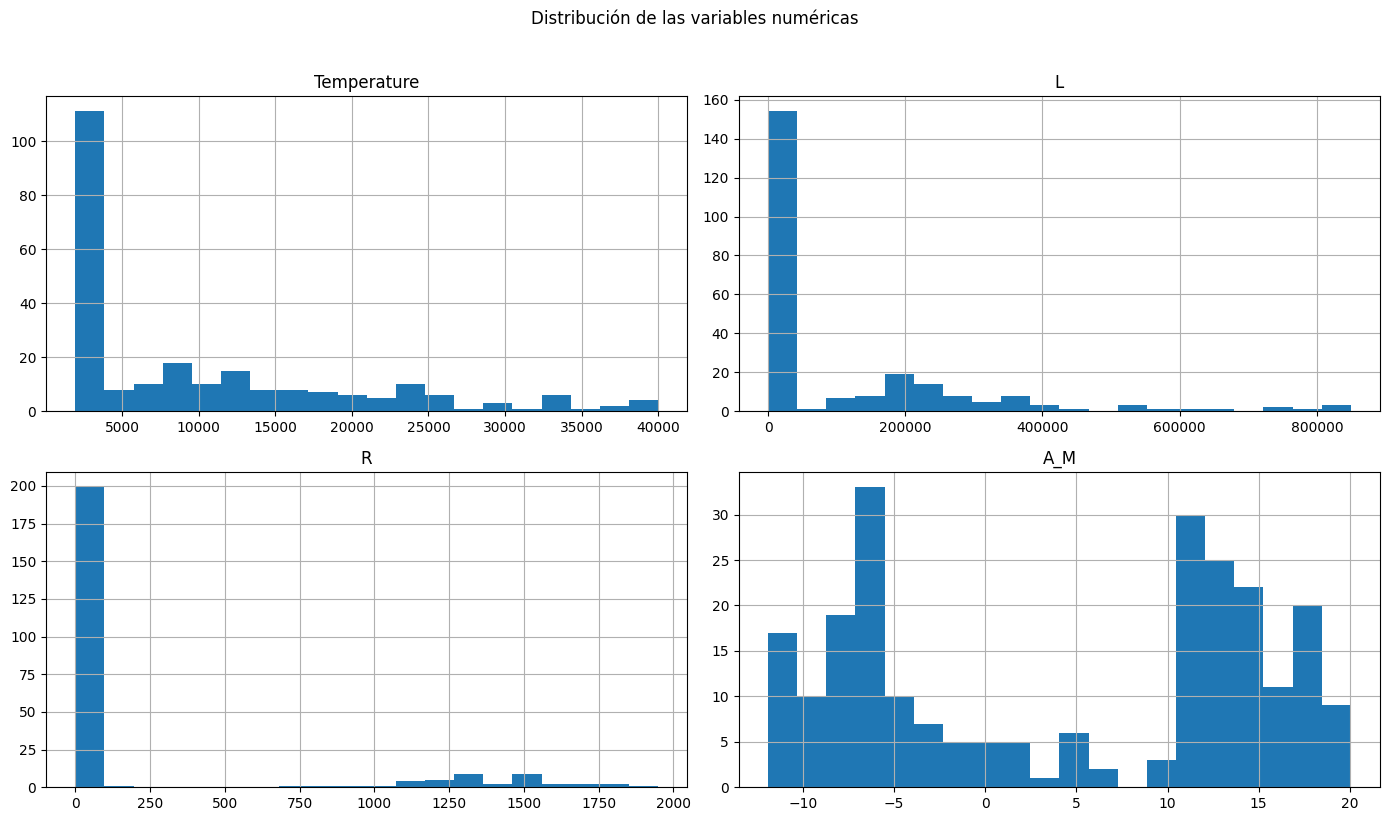

In [4]:
import matplotlib.pyplot as plt

# Selección de variables numéricas
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Variables numéricas del dataset:")
print(num_cols)

print("\nResumen estadístico de las variables numéricas:")
display(df[num_cols].describe().T)

# Histogramas
df[num_cols].hist(figsize=(14, 8), bins=20)
plt.suptitle("Distribución de las variables numéricas", y=1.02)
plt.tight_layout()
plt.show()

## 3.4 Posibles columnas id

En esta sección se revisa si alguna de las variables del dataset puede estar actuando como identificador de las features. Este tipo de columnas no le aportan al modelo información relevante y por lo tanto no se deben incluir como parte del dataset para entrenar el modelo.

In [5]:
print("Número de valores únicos por columna:")
display(df.nunique())

Número de valores únicos por columna:


Temperature       228
L                 208
R                 216
A_M               228
Color              17
Spectral_Class      7
dtype: int64

No se observa ninguna variable que actúe como identificador. Aunque algunas variables numéricas presentan una gran cantidad de valores distintos, esto es de esperar al tratarse de atributos continuos. Por tanto, **no es necesario eliminar nunguna columna** por este motivo.

## 3.5 Valores atípicos

A continuación se estudia la posible presencia de valores atípicos en las varibles numéricas. Detectar estas variables es importante, ya que pueden influir en la representación de los datos y en el comportamiento de algunos algoritmos de clustering.

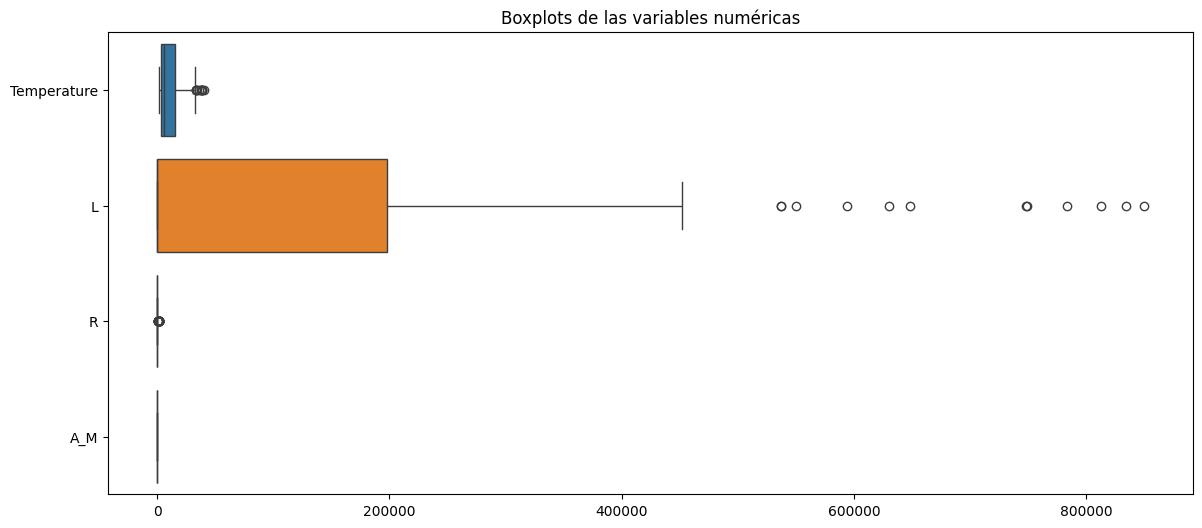

In [6]:
import seaborn as sns

plt.figure(figsize=(14, 6))
sns.boxplot(data=df[num_cols], orient="h")
plt.title("Boxplots de las variables numéricas")
plt.show()

Los boxplots permiten confirmar la presencia de **valores atípicos**, especialmente en la variable `L`, que presenta varias features muy alejadas del resto. También se observan puntos extremos en `Temperature`, aunque de forma menos pronunciada. No obstante, diferencia de escala entre las variables dificulta la interpretación. Esto refuerza la idea de que será necesario aplicar **escalado** antes de utilizar técnicas como PCA o clustering.

Ahora, para analizar correctamente las variables se realizará un boxplot por cada una de ellas.

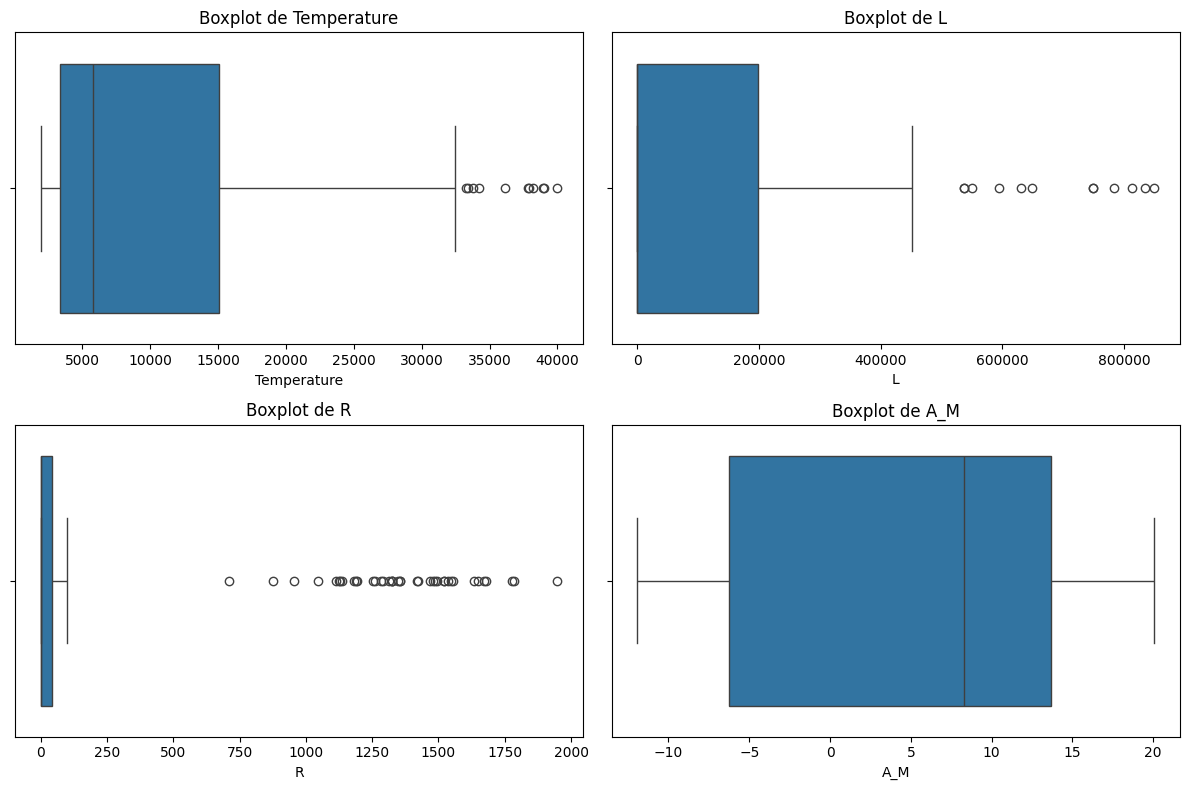

In [7]:
num_cols = ["Temperature", "L", "R", "A_M"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

En este análisis, se puede observar que los boxplots confirman la presencia de valores atípicos. Estos valores son especialmente notorios en `L` y `R`. `Temperature` también presenta algunos valores extremos , aunque de forma menos pronunciada. Por su parte, `A_M` muestra una distribución más equilibrada y sin outliers tan marcados. Esto indica que existen variables presentan una gran dispersión. Esto se deberá tener en cuenta en el preprocesado y en la interpretación de los resultados del clustering.

## 3.6 Valores presentes en las variables categóricas

Ahora se pasará a analizar las variables categóricas del dataset. El objetivo es **identificar los valores presentes** en cada una de ellas y comprobar si existen inconsistencias en su representación. Esto es esencial para la práctica, ya que estas variables deberán transformarse posteriormente mediante **codificación ordinal** antes de aplicar PCA.

In [8]:
# Selección de columnas categóricas
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

print("Variables categóricas del dataset")
print(cat_cols)

for col in cat_cols:
    print(f"\nColumna: {col}")
    print(f"Número de categorías: {df[col].nunique()}")
    print("Frecuencia de cada categoría:")
    display(df[col].value_counts())

    print("Valores únicos")
    print(sorted(df[col].unique()))

Variables categóricas del dataset
['Color', 'Spectral_Class']

Columna: Color
Número de categorías: 17
Frecuencia de cada categoría:


Color
Red                   112
Blue                   56
Blue-white             26
Blue White             10
yellow-white            8
White                   7
Blue white              4
Yellowish White         3
white                   3
Whitish                 2
Orange                  2
yellowish               2
Pale yellow orange      1
White-Yellow            1
Yellowish               1
Orange-Red              1
Blue-White              1
Name: count, dtype: int64

Valores únicos
['Blue', 'Blue White', 'Blue white', 'Blue-White', 'Blue-white', 'Orange', 'Orange-Red', 'Pale yellow orange', 'Red', 'White', 'White-Yellow', 'Whitish', 'Yellowish', 'Yellowish White', 'white', 'yellow-white', 'yellowish']

Columna: Spectral_Class
Número de categorías: 7
Frecuencia de cada categoría:


Spectral_Class
M    111
B     46
O     40
A     19
F     17
K      6
G      1
Name: count, dtype: int64

Valores únicos
['A', 'B', 'F', 'G', 'K', 'M', 'O']


Este análisis muestra que `Spectral_Class` tiene una estructura **limpia**, con **7 categorías** bien definidas, lo que hará más fácil su codificación ordinal posterior. Sin embargo, la variable `Color` contiene **17 categorías**, varias de las cuales parecen corresponder a formas distintas de representar los mismos colores, como es el caso con `Blue-white`, `Blue White`, `Blue white`o `Blue-White`, así como con `White` y `white` y otras variables similares.

Esto indica que, antes de aplicar codificación ordinal, es necesario realizar una **limpieza y unificación de etiquetas** en la variable `Color`, con el fin de evitar que diferencias únicamente de escritura generen categorías distintas.

## 4. Preprocesado y reducción de dimensionalidad

Una vez completado el EDA, el siguiente paso consiste en preparar los datos para aplicar clustering. Para ello, primero se limpian y codifican de forma **ordinal** las variables `Color` y `Spectral_Class` categóricas las variables categóricas (`Color` y `Spectral_Class`). Después, se escalan todas las variables y se aplica **PCA** para proyectar los datos en dos dimensiones.

### 4.1 Limpieza y codificación ordinal de variables categóricas

La variable `Spectral_Class` ya aparece con una notación homogénea, pero `Color` contiene inconsistencias de escritura y algunas etiquetas intermedias con muy pocas observaciones. Por tanto, primero normalizamos las cadenas y después agrupamos esos valores en familias principales de color para evitar niveles ordinales artificiales.

A continuación asignamos códigos ordinales con el criterio de que valores más altos representen estrellas **más calientes y energéticas**. Así, para `Spectral_Class` se sigue la secuencia térmica `M < K < G < F < A < B < O`, y para `Color` utilizamos `red < orange < yellow < yellow white < white < blue white < blue`.

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df_model = df.copy()

df_model['Color_clean'] = (
    df_model['Color']
    .str.lower()
    .str.strip()
    .str.replace('-', ' ', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
)

color_unification = {
    'red': 'red',
    'orange red': 'orange',
    'orange': 'orange',
    'pale yellow orange': 'yellow',
    'yellowish': 'yellow',
    'yellow': 'yellow',
    'yellowish white': 'yellow white',
    'yellow white': 'yellow white',
    'white yellow': 'yellow white',
    'white': 'white',
    'whitish': 'white',
    'blue white': 'blue white',
    'blue': 'blue'
}

df_model['Color_clean'] = df_model['Color_clean'].replace(color_unification)

spectral_map = {'M': 0, 'K': 1, 'G': 2, 'F': 3, 'A': 4, 'B': 5, 'O': 6}
color_map = {
    'red': 0,
    'orange': 1,
    'yellow': 2,
    'yellow white': 3,
    'white': 4,
    'blue white': 5,
    'blue': 6
}

unknown_colors = sorted(set(df_model['Color_clean']) - set(color_map))
unknown_spectral = sorted(set(df_model['Spectral_Class']) - set(spectral_map))

if unknown_colors:
    raise ValueError(f'Hay colores sin mapear: {unknown_colors}')
if unknown_spectral:
    raise ValueError(f'Hay clases espectrales sin mapear: {unknown_spectral}')

color_mapping_df = pd.DataFrame({
    'Color normalizado': list(color_map.keys()),
    'Código ordinal': list(color_map.values())
})

spectral_mapping_df = pd.DataFrame({
    'Clase espectral': list(spectral_map.keys()),
    'Código ordinal': list(spectral_map.values())
})

display(pd.DataFrame({
    'Color original': sorted(df['Color'].unique()),
}))

display(
    df_model[['Color', 'Color_clean']]
    .drop_duplicates()
    .sort_values(['Color_clean', 'Color'])
    .reset_index(drop=True)
)

display(color_mapping_df)
display(spectral_mapping_df)

df_model['Color'] = df_model['Color_clean'].map(color_map)
df_model['Spectral_Class'] = df_model['Spectral_Class'].map(spectral_map)
df_model = df_model.drop(columns=['Color_clean'])

display(df_model.head())

,Color original
0,Blue
1,Blue White
2,Blue white
3,Blue-White
4,Blue-white
5,Orange
6,Orange-Red
7,Pale yellow orange
8,Red
9,White


,Color,Color_clean
0,Blue,blue
1,Blue White,blue white
2,Blue white,blue white
3,Blue-White,blue white
4,Blue-white,blue white
5,Orange,orange
6,Orange-Red,orange
7,Red,red
8,White,white
9,Whitish,white


,Color normalizado,Código ordinal
0,red,0
1,orange,1
2,yellow,2
3,yellow white,3
4,white,4
5,blue white,5
6,blue,6


,Clase espectral,Código ordinal
0,M,0
1,K,1
2,G,2
3,F,3
4,A,4
5,B,5
6,O,6


,Temperature,L,R,A_M,Color,Spectral_Class
0,3068,0.002400,0.1700,16.12,0,0
1,3042,0.000500,0.1542,16.60,0,0
2,2600,0.000300,0.1020,18.70,0,0
3,2800,0.000200,0.1600,16.65,0,0
4,1939,0.000138,0.1030,20.06,0,0


### 4.2 Escalado de variables y PCA

Antes de aplicar PCA, se estandarizan todas las variables para evitar que atributos con magnitudes mucho mayores, como `L` o `R`, dominen el análisis. Después se ajusta PCA sobre los datos escalados y se estudia cuánta varianza explican las componentes principales.

Comprobación rápida del escalado (medias ~ 0 y desviaciones típicas ~ 1):


,Temperature,L,R,A_M,Color,Spectral_Class
media,-0.0,0.0,-0.0,-0.0,0.0,-0.0
desv_tipica,1.0,1.0,1.0,1.0,1.0,1.0


,Componente,Varianza explicada,Varianza acumulada
0,PC1,55.76%,55.76%
1,PC2,29.59%,85.35%
2,PC3,6.36%,91.71%
3,PC4,4.75%,96.46%
4,PC5,3.38%,99.83%
5,PC6,0.17%,100.00%


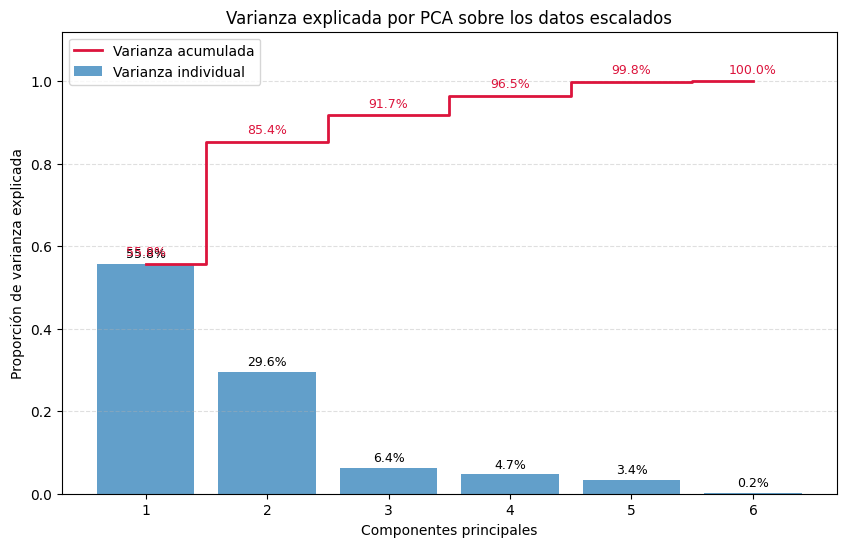

In [10]:
feature_names = df_model.columns.tolist()
X = df_model[feature_names]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
df_scaled = pd.DataFrame(X_scaled, columns=feature_names)

scaling_check = pd.DataFrame(
    [df_scaled.mean(), df_scaled.std(ddof=0)],
    index=['media', 'desv_tipica']
)

print('Comprobación rápida del escalado (medias ~ 0 y desviaciones típicas ~ 1):')
display(scaling_check.round(6))

pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_df = pd.DataFrame({
    'Componente': [f'PC{i}' for i in range(1, len(explained_variance) + 1)],
    'Varianza explicada': explained_variance,
    'Varianza acumulada': cumulative_variance
})

display(
    variance_df.style.format({
        'Varianza explicada': '{:.2%}',
        'Varianza acumulada': '{:.2%}'
    })
)

plt.figure(figsize=(10, 6))
plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    alpha=0.7,
    label='Varianza individual'
)
plt.step(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    where='mid',
    color='crimson',
    linewidth=2,
    label='Varianza acumulada'
)

for i, (ev, cv) in enumerate(zip(explained_variance, cumulative_variance), start=1):
    plt.text(i, ev + 0.015, f'{ev:.1%}', ha='center', fontsize=9)
    plt.text(i, cv + 0.02, f'{cv:.1%}', ha='center', color='crimson', fontsize=9)

plt.xlabel('Componentes principales')
plt.ylabel('Proporción de varianza explicada')
plt.title('Varianza explicada por PCA sobre los datos escalados')
plt.ylim(0, 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend()
plt.show()

Las dos primeras componentes principales concentran alrededor del **85%** de la varianza total, con una aportación claramente mayor de `PC1` que de `PC2`. Esto justifica trabajar en dos dimensiones en los apartados de clustering, ya que se conserva la mayor parte de la estructura del problema sin renunciar a una visualización clara. Además, con 4 componentes ya se supera aproximadamente el **96%** de varianza acumulada, lo que sugiere que existe redundancia entre algunas variables originales.

Cargas de las variables originales sobre las dos primeras componentes:


,PC1,PC2
Temperature,0.469,-0.217
L,0.368,0.405
R,0.170,0.637
A_M,-0.399,-0.405
Color,0.472,-0.343
Spectral_Class,0.483,-0.319


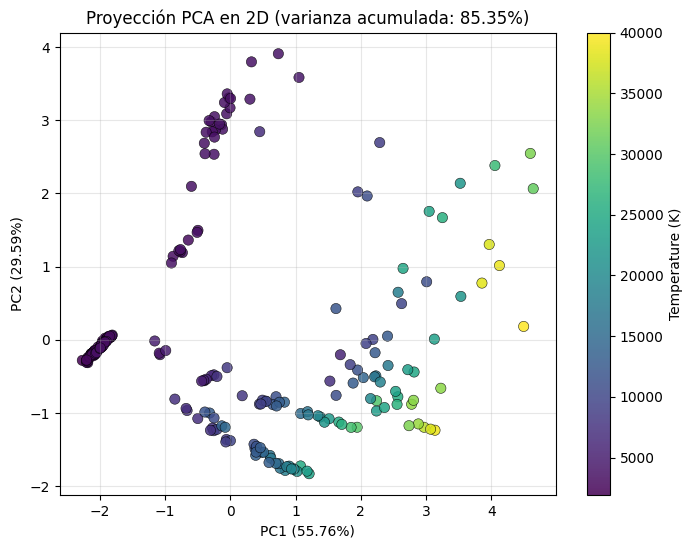

,PC1,PC2
0,-2.065267,-0.154712
1,-2.084765,-0.172619
2,-2.186224,-0.243462
3,-2.098573,-0.169023
4,-2.270366,-0.280759


In [11]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])

loadings_df = pd.DataFrame(
    pca_2d.components_.T,
    index=feature_names,
    columns=['PC1', 'PC2']
)

print('Cargas de las variables originales sobre las dos primeras componentes:')
display(loadings_df.style.format('{:.3f}'))

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df_pca['PC1'],
    df_pca['PC2'],
    c=df_model['Temperature'],
    cmap='viridis',
    s=55,
    edgecolor='black',
    linewidth=0.4,
    alpha=0.85
)
plt.title(
    f'Proyección PCA en 2D (varianza acumulada: {pca_2d.explained_variance_ratio_.sum():.2%})'
)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.2%})')
plt.grid(alpha=0.3)
plt.colorbar(scatter, label='Temperature (K)')
plt.show()

display(df_pca.head())

Las cargas del PCA indican que la primera componente principal (`PC1`) recoge sobre todo información relacionada con la temperatura de la estrella, ya que las variables con mayor peso son `Spectral_Class`, `Temperature` y `Color`. Por tanto, esta componente puede interpretarse como un eje que separa estrellas más frías de estrellas más calientes. La segunda componente (`PC2`) está más relacionada con el tamaño y la luminosidad, porque las variables con mayor contribución son `R`, `L` y `A_M`. En consecuencia, la proyección en dos dimensiones resume principalmente un eje térmico y otro asociado al tamaño/brillo estelar. El dataframe `df_pca` contiene esa representación reducida y será la entrada de los algoritmos de clustering.

## 5. Algoritmos de clustering

Una vez obtenida la representación de los datos mediante PCA, el siguiente paso consiste en aplicar los tres algoritmos de clustering que se van a comparar: K-Means, clustering jerárquico y DBSCAN. A partir de este punto, todos los modelos se entrenan directamente sobre `X_pca`, es decir, sobre las dos componentes principales calculadas anteriormente.

De esta forma, todos los métodos trabajan sobre el mismo espacio bidimensional, lo que facilita tanto la comparación de resultados como su visualización.

### 5.1 K-Means

En primer lugar se aplica el algoritmo **K-Means**. Este método necesita fijar previamente el número de clusters, por lo que se prueban distintos valores de `k` entre 2 y 10.

Para comparar las distintas configuraciones se utiliza la **inercia** y el **coeficiente de Silhouette**, que son las métricas vistas en clase para estudiar el número de clusters en K-Means. La métrica principal para escoger el valor de `k` será Silhouette, mientras que la inercia se utilizará como apoyo visual mediante el método del codo.

Mejor k según Silhouette: 6
Silhouette asociado: 0.6533


k,Inercia,Silhouette
2,607.06,0.5095
3,335.20,0.5826
4,172.46,0.6281
5,108.87,0.6420
6,84.96,0.6533
7,64.57,0.6397
8,54.87,0.6346
9,48.15,0.6097
10,42.48,0.6235


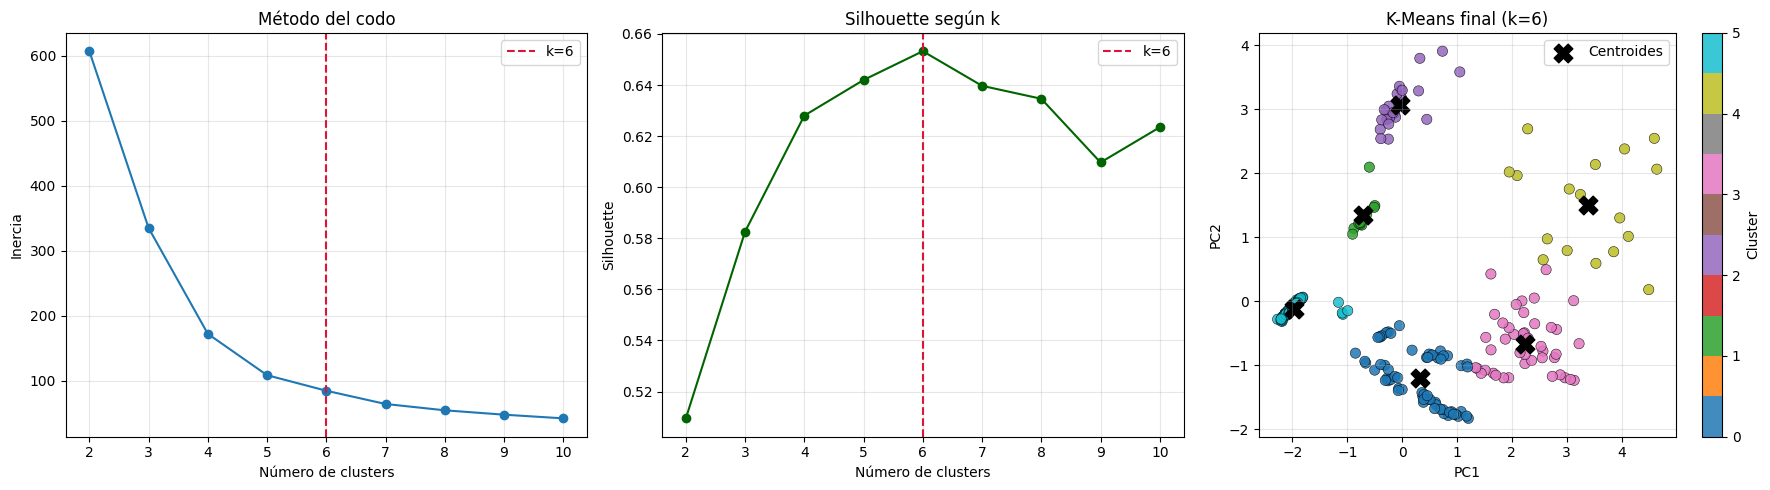

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
kmeans_results = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    labels = kmeans.fit_predict(X_pca)

    kmeans_results.append({
        'k': k,
        'Inercia': kmeans.inertia_,
        'Silhouette': silhouette_score(X_pca, labels)
    })

kmeans_results_df = pd.DataFrame(kmeans_results)
best_kmeans_row = kmeans_results_df.loc[kmeans_results_df['Silhouette'].idxmax()]
best_kmeans_k = int(best_kmeans_row['k'])
best_kmeans_score = float(best_kmeans_row['Silhouette'])

print(f'Mejor k según Silhouette: {best_kmeans_k}')
print(f'Silhouette asociado: {best_kmeans_score:.4f}')

display(
    kmeans_results_df.style
    .format({
        'Inercia': '{:.2f}',
        'Silhouette': '{:.4f}'
    })
    .hide(axis='index')
)

kmeans_final = KMeans(n_clusters=best_kmeans_k, random_state=SEED, n_init=20)
labels_kmeans = kmeans_final.fit_predict(X_pca)
df_pca['Cluster_KMeans'] = labels_kmeans

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(kmeans_results_df['k'], kmeans_results_df['Inercia'], marker='o')
axes[0].axvline(best_kmeans_k, color='crimson', linestyle='--', label=f'k={best_kmeans_k}')
axes[0].set_title('Método del codo')
axes[0].set_xlabel('Número de clusters')
axes[0].set_ylabel('Inercia')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(kmeans_results_df['k'], kmeans_results_df['Silhouette'], marker='o', color='darkgreen')
axes[1].axvline(best_kmeans_k, color='crimson', linestyle='--', label=f'k={best_kmeans_k}')
axes[1].set_title('Silhouette según k')
axes[1].set_xlabel('Número de clusters')
axes[1].set_ylabel('Silhouette')
axes[1].grid(alpha=0.3)
axes[1].legend()

scatter = axes[2].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_kmeans,
    cmap='tab10',
    s=55,
    edgecolor='black',
    linewidth=0.4,
    alpha=0.85
)
axes[2].scatter(
    kmeans_final.cluster_centers_[:, 0],
    kmeans_final.cluster_centers_[:, 1],
    c='black',
    marker='X',
    s=180,
    label='Centroides'
)
axes[2].set_title(f'K-Means final (k={best_kmeans_k})')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].grid(alpha=0.3)
axes[2].legend()

plt.colorbar(scatter, ax=axes[2], label='Cluster')
plt.tight_layout()
plt.show()

A partir de los resultados obtenidos, K-Means selecciona `k = 6` como mejor configuración según el coeficiente de Silhouette. Este resultado es razonable para el problema, ya que permite trabajar con el mismo número de grupos que las clases astronómicas de referencia.

En la representación PCA se observan grupos bastante definidos. Además, K-Means tiene la ventaja de asignar todas las estrellas a un cluster, sin dejar observaciones sin clasificar.

### 5.2 Clustering jerárquico

A continuación se aplica **clustering jerárquico aglomerativo**. En este caso se prueban varias funciones de enlace (`ward`, `complete`, `average` y `single`) junto con distintos números de clusters.

El dendrograma permite visualizar el proceso de agrupación y observar a qué distancia se van fusionando los grupos. Por tanto, además de las métricas numéricas, este método proporciona una herramienta útil para interpretar la estructura de los datos.

Mejor clustering jerárquico: linkage=complete, k=8
Silhouette asociado: 0.6433
Mejores combinaciones ordenadas por Silhouette:


Linkage,k,Silhouette
complete,8,0.6433
average,7,0.6380
complete,6,0.6353
complete,9,0.6344
average,5,0.6341
average,8,0.6339
ward,7,0.6305
ward,9,0.6289
ward,8,0.6262
complete,7,0.6244


Matriz de Silhouette por linkage y número de clusters:


Linkage,average,complete,single,ward
k,,,,
2,0.3971,0.3815,0.3717,0.4950
3,0.4986,0.4855,0.2850,0.5633
4,0.6015,0.5846,0.2529,0.6178
5,0.6341,0.6164,0.2975,0.6134
6,0.6194,0.6353,0.2829,0.6134
7,0.6380,0.6244,0.4987,0.6305
8,0.6339,0.6433,0.4025,0.6262
9,0.6175,0.6344,0.3190,0.6289
10,0.6180,0.6118,0.3577,0.6237


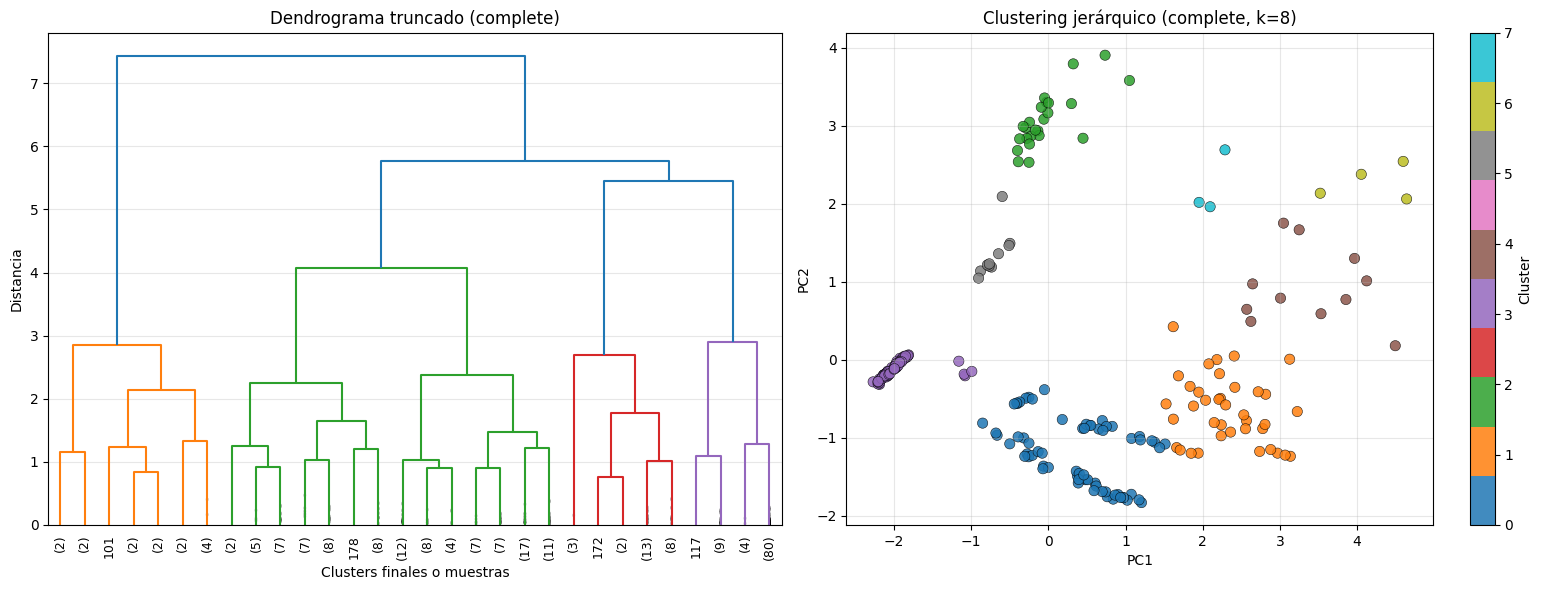

In [13]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

linkage_methods = ['ward', 'complete', 'average', 'single']
hc_results = []

for linkage_method in linkage_methods:
    for k in range(2, 11):
        hc = AgglomerativeClustering(
            n_clusters=k,
            metric='euclidean',
            linkage=linkage_method
        )
        labels = hc.fit_predict(X_pca)

        hc_results.append({
            'Linkage': linkage_method,
            'k': k,
            'Silhouette': silhouette_score(X_pca, labels)
        })

hc_results_df = pd.DataFrame(hc_results)
best_hc_row = hc_results_df.loc[hc_results_df['Silhouette'].idxmax()]
best_hc_linkage = str(best_hc_row['Linkage'])
best_hc_k = int(best_hc_row['k'])
best_hc_score = float(best_hc_row['Silhouette'])

print(f'Mejor clustering jerárquico: linkage={best_hc_linkage}, k={best_hc_k}')
print(f'Silhouette asociado: {best_hc_score:.4f}')

print('Mejores combinaciones ordenadas por Silhouette:')
display(
    hc_results_df
    .sort_values('Silhouette', ascending=False)
    .head(10)
    .style
    .format({'Silhouette': '{:.4f}'})
    .hide(axis='index')
)

print('Matriz de Silhouette por linkage y número de clusters:')
hc_silhouette_pivot = hc_results_df.pivot(index='k', columns='Linkage', values='Silhouette')
display(hc_silhouette_pivot.style.format('{:.4f}'))

hc_final = AgglomerativeClustering(
    n_clusters=best_hc_k,
    metric='euclidean',
    linkage=best_hc_linkage
)
labels_hc = hc_final.fit_predict(X_pca)
df_pca['Cluster_Hierarchical'] = labels_hc

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

Z = linkage(X_pca, method=best_hc_linkage, metric='euclidean')
dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    show_contracted=True,
    leaf_rotation=90,
    leaf_font_size=9,
    ax=axes[0]
)
axes[0].set_title(f'Dendrograma truncado ({best_hc_linkage})')
axes[0].set_xlabel('Clusters finales o muestras')
axes[0].set_ylabel('Distancia')
axes[0].grid(axis='y', alpha=0.3)

scatter = axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_hc,
    cmap='tab10',
    s=55,
    edgecolor='black',
    linewidth=0.4,
    alpha=0.85
)
axes[1].set_title(f'Clustering jerárquico ({best_hc_linkage}, k={best_hc_k})')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].grid(alpha=0.3)
plt.colorbar(scatter, ax=axes[1], label='Cluster')

plt.tight_layout()
plt.show()

En este caso, la mejor configuración según Silhouette no coincide exactamente con la de K-Means: el clustering jerárquico selecciona un número mayor de grupos. Esto muestra que la estructura de los datos admite diferentes particiones dependiendo del criterio utilizado.

Aunque el dendrograma aporta información interpretativa interesante, para recomendar un pipeline final también hay que tener en cuenta que el objetivo de la práctica es obtener una agrupación clara y comparable con los tipos astronómicos de la tabla.

### 5.3 DBSCAN y métrica DBCV

Por último se aplica **DBSCAN**, un algoritmo basado en densidad. A diferencia de K-Means y del clustering jerárquico, DBSCAN no obliga a clasificar todos los puntos, sino que puede marcar algunas observaciones como ruido.

Por este motivo, no se evalúa únicamente con las métricas anteriores. Para DBSCAN usamos **DBCV**, una métrica diseñada para evaluar agrupaciones basadas en densidad. Como esta métrica no está disponible directamente en `scikit-learn`, se utiliza una implementación externa, siguiendo el enfoque de los notebooks de ejemplo.

In [14]:
# DBCV no está disponible en scikit-learn.
# En caso de no tenerlo instalado, se puede ejecutar:
# !pip install git+https://github.com/FelSiq/DBCV.git

import multiprocessing as mp
from dbcv import dbcv

# Evita problemas de multiprocessing en algunos entornos Linux/Python recientes.
if 'fork' in mp.get_all_start_methods():
    mp.set_start_method('fork', force=True)

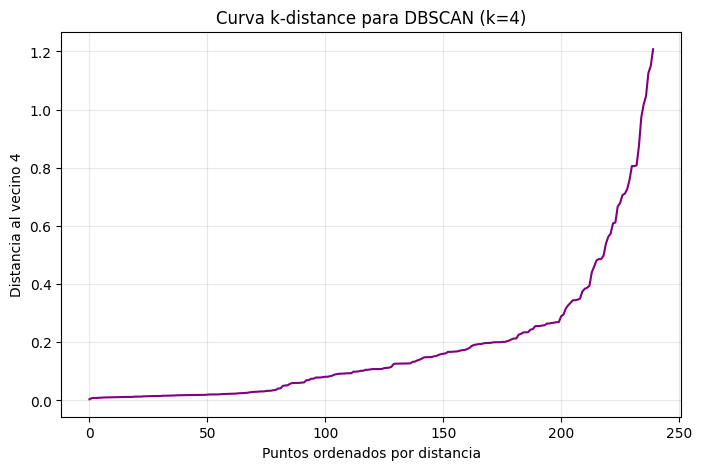

Mejores configuraciones de DBSCAN según DBCV:


eps,min_samples,Clusters,Ruido,% Ruido,DBCV
0.60,6,4,24,10.0%,0.8334
0.50,6,4,26,10.8%,0.8263
0.50,5,4,23,9.6%,0.8226
0.60,5,4,19,7.9%,0.7992
0.20,3,13,38,15.8%,0.7755
0.20,4,12,47,19.6%,0.7444
0.30,6,10,40,16.7%,0.7332
0.30,3,9,30,12.5%,0.7204
0.30,4,9,30,12.5%,0.7204
0.30,5,8,34,14.2%,0.7056


Mejor DBSCAN: eps=0.6, min_samples=6, clusters=4, ruido=24, DBCV=0.8334


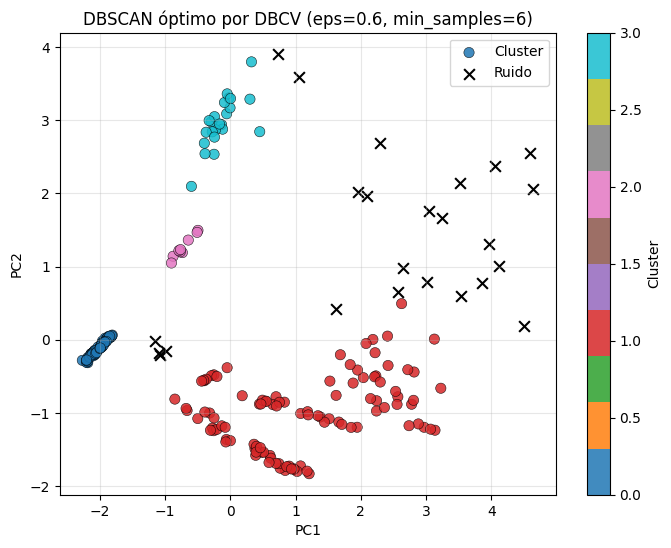

In [15]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

min_samples_heuristic = 2 * X_pca.shape[1]
nearest_neighbors = NearestNeighbors(n_neighbors=min_samples_heuristic)
nearest_neighbors.fit(X_pca)
distances, _ = nearest_neighbors.kneighbors(X_pca)
k_distances = np.sort(distances[:, min_samples_heuristic - 1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances, color='purple')
plt.title(f'Curva k-distance para DBSCAN (k={min_samples_heuristic})')
plt.xlabel('Puntos ordenados por distancia')
plt.ylabel(f'Distancia al vecino {min_samples_heuristic}')
plt.grid(alpha=0.3)
plt.show()

eps_values = [0.20, 0.30, 0.40, 0.50, 0.60]
min_samples_values = [3, 4, 5, 6]

dbscan_results = []
best_dbscan_score = -np.inf
best_dbscan_params = {'eps': None, 'min_samples': None}
best_dbscan_labels = None

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples, metric='euclidean')
        labels = dbscan.fit_predict(X_pca)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = int(np.sum(labels == -1))
        noise_pct = 100 * n_noise / len(labels)
        score = np.nan

        if n_clusters >= 2:
            try:
                score = dbcv(X_pca, labels, n_processes=1)
            except Exception:
                score = np.nan

        dbscan_results.append({
            'eps': eps,
            'min_samples': min_samples,
            'Clusters': n_clusters,
            'Ruido': n_noise,
            '% Ruido': noise_pct,
            'DBCV': score
        })

        if not np.isnan(score) and score > best_dbscan_score:
            best_dbscan_score = float(score)
            best_dbscan_params = {'eps': eps, 'min_samples': min_samples}
            best_dbscan_labels = labels

dbscan_results_df = pd.DataFrame(dbscan_results)

print('Mejores configuraciones de DBSCAN según DBCV:')
display(
    dbscan_results_df
    .dropna(subset=['DBCV'])
    .sort_values('DBCV', ascending=False)
    .style
    .format({'eps': '{:.2f}', '% Ruido': '{:.1f}%', 'DBCV': '{:.4f}'})
    .hide(axis='index')
)

if best_dbscan_labels is None:
    raise ValueError('No se ha encontrado ninguna configuración válida de DBSCAN con al menos dos clusters.')

labels_dbscan = best_dbscan_labels
df_pca['Cluster_DBSCAN'] = labels_dbscan
best_dbscan_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
best_dbscan_noise = int(np.sum(labels_dbscan == -1))

print(
    f"Mejor DBSCAN: eps={best_dbscan_params['eps']}, "
    f"min_samples={best_dbscan_params['min_samples']}, "
    f"clusters={best_dbscan_clusters}, ruido={best_dbscan_noise}, "
    f"DBCV={best_dbscan_score:.4f}"
)

fig, ax = plt.subplots(figsize=(8, 6))
noise_mask = labels_dbscan == -1
cluster_mask = ~noise_mask

scatter = ax.scatter(
    X_pca[cluster_mask, 0],
    X_pca[cluster_mask, 1],
    c=labels_dbscan[cluster_mask],
    cmap='tab10',
    s=55,
    edgecolor='black',
    linewidth=0.4,
    alpha=0.85,
    label='Cluster'
)
ax.scatter(
    X_pca[noise_mask, 0],
    X_pca[noise_mask, 1],
    c='black',
    marker='x',
    s=60,
    label='Ruido'
)
ax.set_title(
    f"DBSCAN óptimo por DBCV (eps={best_dbscan_params['eps']}, "
    f"min_samples={best_dbscan_params['min_samples']})"
)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.grid(alpha=0.3)
ax.legend()
plt.colorbar(scatter, ax=ax, label='Cluster')
plt.show()

La mejor configuración de DBSCAN se obtiene con 4 clusters y 24 puntos etiquetados como ruido.

DBSCAN permite detectar zonas densas y separar observaciones atípicas, lo cual puede ser útil en un conjunto de datos con estrellas muy extremas. Sin embargo, en este problema interesa obtener una clasificación suficientemente completa y comparable con las clases astronómicas.

La presencia de observaciones etiquetadas ocmo ruido es coherente con el EDA realizado, donde se detectaron valores atípicos especialmente en las variables `L` y `R`. DBSCAN, al basarse en densidad, puede identificar como ruido aquellos puntos que se encuentran en regiones poco densas del PCA. 

La mejor configuración de DBSCAN según DBCV obtiene menos clusters que K-Means y deja algunas observaciones etiquetadas como ruido. Por tanto, aunque el método aporta una perspectiva interesante, no parece el más adecuado como pipeline final para este caso.

## 6. Comparación de resultados y pipeline recomendado

Una vez ajustados los hiperparámetros de los tres métodos, se comparan sus mejores configuraciones. En K-Means y clustering jerárquico se utiliza principalmente el coeficiente de Silhouette, mientras que en DBSCAN se utiliza DBCV.

Además de las métricas, también se tiene en cuenta la interpretación del resultado: número de clusters obtenidos, presencia de puntos de ruido y facilidad para comparar las agrupaciones con las clases astronómicas de referencia.

Algoritmo,Hiperparámetros,Clusters,Ruido,Métrica principal,Valor
K-Means,k=6,6,0,Silhouette,0.6533
Jerárquico,"linkage=complete, k=8",8,0,Silhouette,0.6433
DBSCAN,"eps=0.6, min_samples=6",4,24,DBCV,0.8334


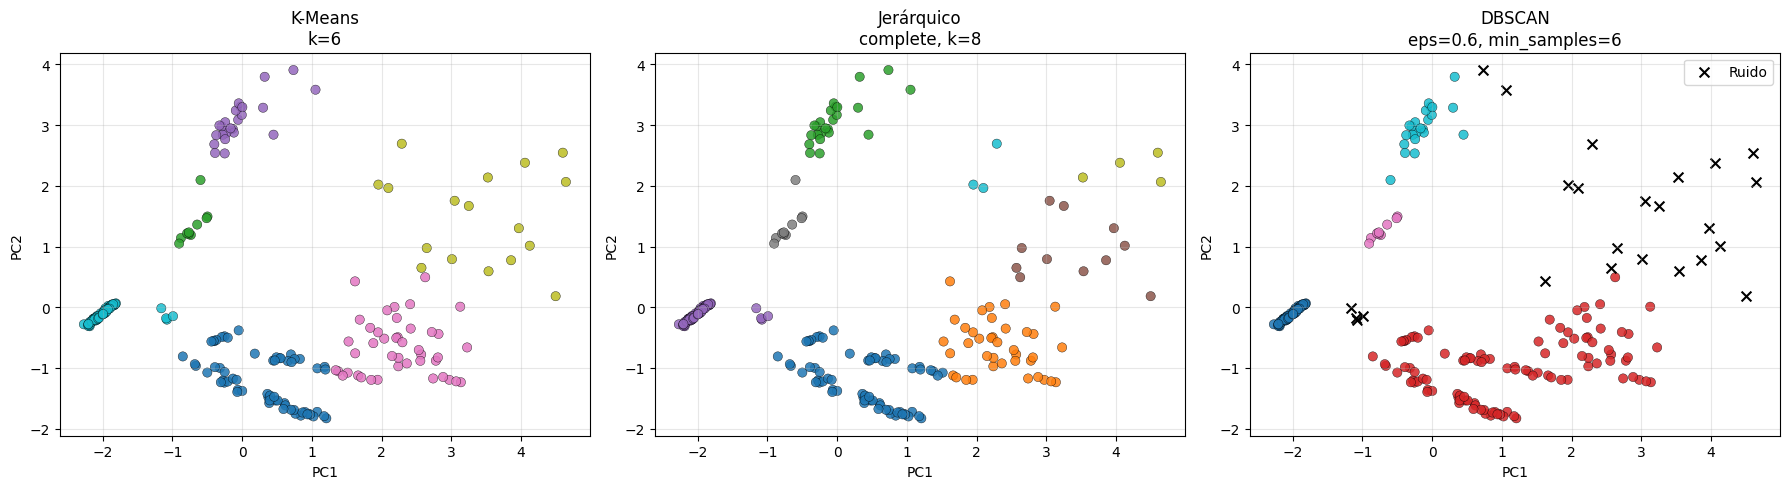

In [16]:
comparison_df = pd.DataFrame([
    {
        'Algoritmo': 'K-Means',
        'Hiperparámetros': f'k={best_kmeans_k}',
        'Clusters': best_kmeans_k,
        'Ruido': 0,
        'Métrica principal': 'Silhouette',
        'Valor': best_kmeans_score
    },
    {
        'Algoritmo': 'Jerárquico',
        'Hiperparámetros': f'linkage={best_hc_linkage}, k={best_hc_k}',
        'Clusters': best_hc_k,
        'Ruido': 0,
        'Métrica principal': 'Silhouette',
        'Valor': best_hc_score
    },
    {
        'Algoritmo': 'DBSCAN',
        'Hiperparámetros': f"eps={best_dbscan_params['eps']}, min_samples={best_dbscan_params['min_samples']}",
        'Clusters': best_dbscan_clusters,
        'Ruido': best_dbscan_noise,
        'Métrica principal': 'DBCV',
        'Valor': best_dbscan_score
    }
])

display(
    comparison_df.style
    .format({'Valor': '{:.4f}'})
    .hide(axis='index')
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plots = [
    ('K-Means', labels_kmeans, f'k={best_kmeans_k}'),
    ('Jerárquico', labels_hc, f'{best_hc_linkage}, k={best_hc_k}'),
    ('DBSCAN', labels_dbscan, f"eps={best_dbscan_params['eps']}, min_samples={best_dbscan_params['min_samples']}")
]

for ax, (title, labels, subtitle) in zip(axes, plots):
    noise_mask = labels == -1
    regular_mask = ~noise_mask

    ax.scatter(
        X_pca[regular_mask, 0],
        X_pca[regular_mask, 1],
        c=labels[regular_mask],
        cmap='tab10',
        s=45,
        edgecolor='black',
        linewidth=0.3,
        alpha=0.85
    )

    if noise_mask.any():
        ax.scatter(
            X_pca[noise_mask, 0],
            X_pca[noise_mask, 1],
            c='black',
            marker='x',
            s=50,
            label='Ruido'
        )
        ax.legend()

    ax.set_title(f'{title}\n{subtitle}')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

A partir de la comparación anterior, el pipeline recomendado es **codificación ordinal → escalado estándar → PCA con 2 componentes → K-Means**.

La elección de K-Means se justifica porque obtiene la mejor puntuación de Silhouette entre los métodos que asignan todas las estrellas a un grupo. Además, selecciona `k = 6`, que permite comparar directamente los clusters obtenidos con las seis clases astronómicas de referencia.

DBSCAN resulta útil para detectar posibles observaciones atípicas, pero obtiene menos grupos y deja puntos como ruido. Sin embargo, obtiene menos grupos y no asigna todas las observaciones a un cluster, lo que dificulta su uso en este caso. Además, su rendimiento se evalúa mediante **DBCV**, una métrica que es específica para clustering basado en densidad, por lo que su valor no es comparable directamente con el Silhouette obtenido por K-Means y clustering jerárquico.

Por su parte, el clustering jerárquico también ofrece una interpretación interesante mediante el dendrograma, aunque su mejor configuración según Silhouette no coincide con seis grupos.

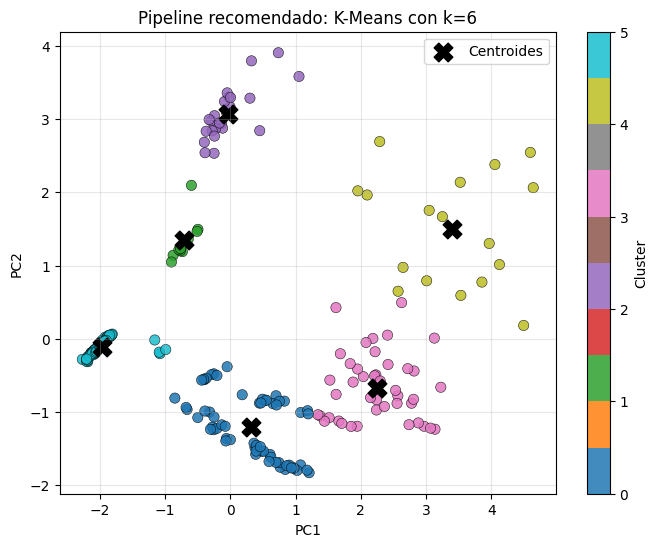

,Temperature,L,R,A_M,Color,Spectral_Class,Cluster_Final
0,3068,0.002400,0.1700,16.12,Red,M,5
1,3042,0.000500,0.1542,16.60,Red,M,5
2,2600,0.000300,0.1020,18.70,Red,M,5
3,2800,0.000200,0.1600,16.65,Red,M,5
4,1939,0.000138,0.1030,20.06,Red,M,5


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

def transformar_ordinales(X_in):
    X_df = X_in.copy()

    X_df['Color'] = (
        X_df['Color']
        .str.lower()
        .str.strip()
        .str.replace('-', ' ', regex=False)
        .str.replace(r'\s+', ' ', regex=True)
        .replace(color_unification)
        .map(color_map)
    )
    X_df['Spectral_Class'] = X_df['Spectral_Class'].map(spectral_map)

    if X_df[feature_names].isnull().any().any():
        missing_cols = X_df[feature_names].columns[X_df[feature_names].isnull().any()].tolist()
        raise ValueError(f'Hay valores sin codificar en las columnas: {missing_cols}')

    return X_df[feature_names]

pipeline_recomendado = Pipeline([
    ('ordinal_encoder', FunctionTransformer(transformar_ordinales, validate=False)),
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2)),
    ('clustering', KMeans(n_clusters=best_kmeans_k, random_state=SEED, n_init=20))
])

labels_finales = pipeline_recomendado.fit_predict(df)
df_resultados = df.copy()
df_resultados['Cluster_Final'] = labels_finales

X_pca_final = pipeline_recomendado[:-1].transform(df)
centroides_finales = pipeline_recomendado.named_steps['clustering'].cluster_centers_

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca_final[:, 0],
    X_pca_final[:, 1],
    c=labels_finales,
    cmap='tab10',
    s=55,
    edgecolor='black',
    linewidth=0.4,
    alpha=0.85
)
plt.scatter(
    centroides_finales[:, 0],
    centroides_finales[:, 1],
    c='black',
    marker='X',
    s=180,
    label='Centroides'
)
plt.title(f'Pipeline recomendado: K-Means con k={best_kmeans_k}')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(alpha=0.3)
plt.legend()
plt.colorbar(scatter, label='Cluster')
plt.show()

display(df_resultados.head())

## 7. Comparación con las clases astronómicas

Finalmente, se comparan los clusters del pipeline recomendado con las clases astronómicas de referencia. Para ello, se vuelve a trabajar con las variables originales y se calcula un resumen de las características de cada cluster.

Como las etiquetas asignadas por K-Means son arbitrarias, se reordenan los clusters según su temperatura media. Esto facilita la interpretación física de los grupos y permite compararlos de forma más clara con los tipos de estrellas de referencia.

Resumen de los clusters finales ordenados por temperatura media:


,n,T_media,T_mediana,L_media,L_mediana,R_media,R_mediana,A_M_media,A_M_mediana,Color_moda,Clase_espectral_moda
Cluster_Ordenado,,,,,,,,,,,
0,84,3214,3186,0.0175,0.000968,0.262,0.161,14.60,14.78,red,M
1,10,3467,3574,2.07e+05,1.98e+05,130,37,-6.80,-6.67,red,M
2,24,3782,3612,2.46e+05,2.19e+05,1.39e+03,1.38e+03,-9.92,-10.70,red,M
3,62,12522,12054,134,0.00128,1.25,0.0122,8.42,11.45,blue white,B
4,43,21517,22350,2.12e+05,2.04e+05,53.5,35,-5.59,-5.91,blue,O
5,17,24847,24490,5.08e+05,4.05e+05,1.17e+03,1.25e+03,-8.82,-8.84,blue,O


,Cluster ordenado,Correspondencia aproximada,Justificación
0,0,Enana roja / enana marrón,"Temperatura baja, luminosidad y radio muy pequ..."
1,1,Supergigante roja,"Temperatura baja, pero luminosidad alta y radi..."
2,2,Hipergigante roja,Radio extremadamente grande y magnitud absolut...
3,3,Enana blanca / secuencia principal,Temperaturas medias-altas con radios pequeños ...
4,4,Supergigante,"Luminosidad alta, radio medio alrededor del or..."
5,5,Hipergigante,"Luminosidad y radio extremos, magnitud absolut..."


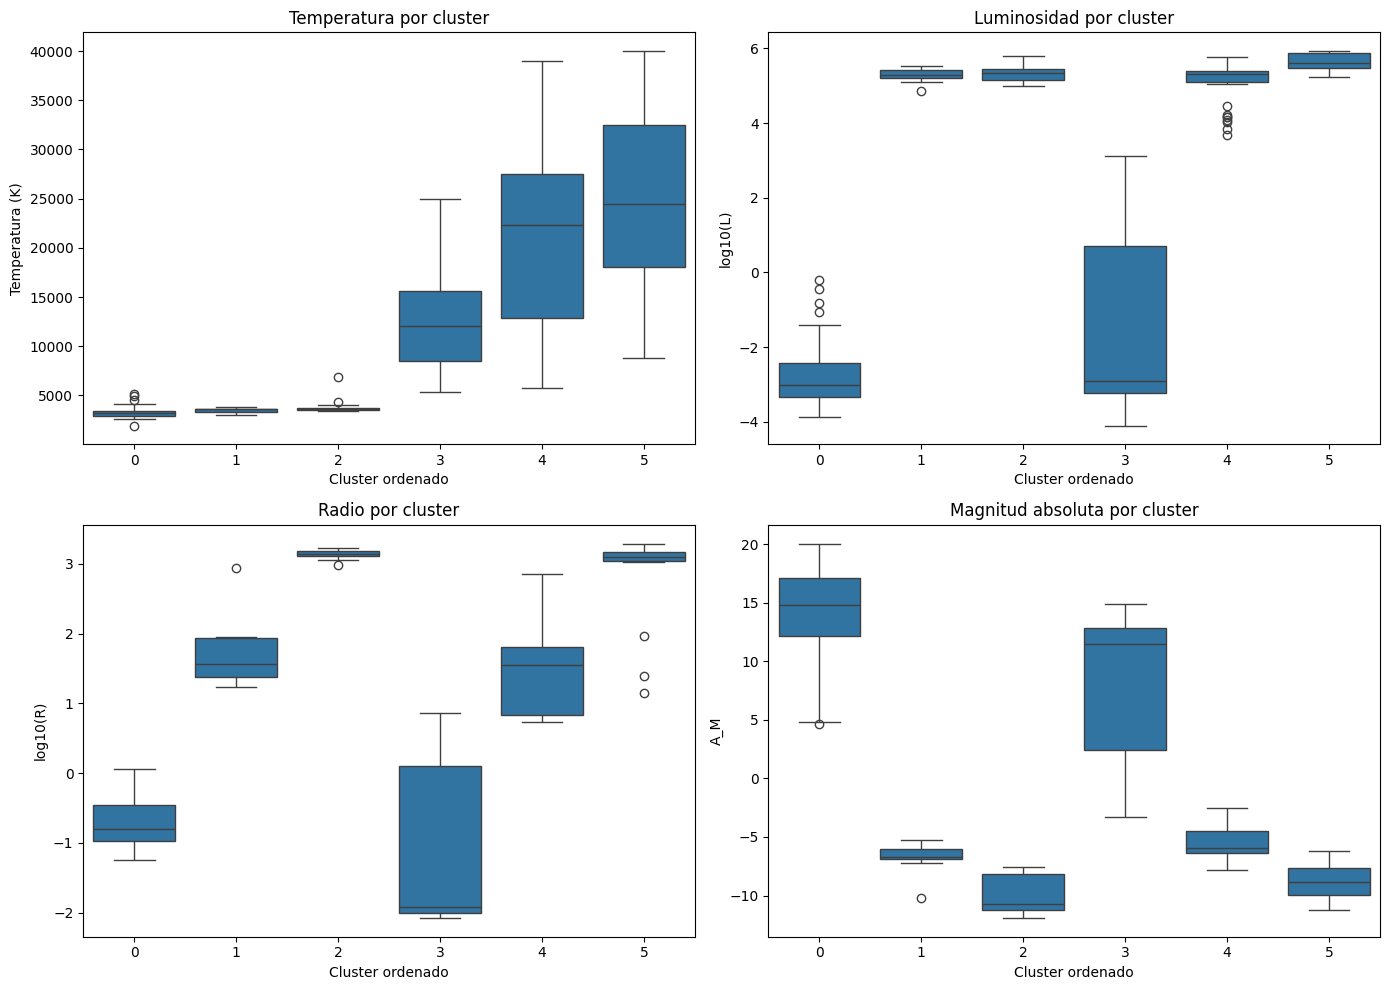

In [18]:
df_resultados['Color_normalizado'] = (
    df_resultados['Color']
    .str.lower()
    .str.strip()
    .str.replace('-', ' ', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
    .replace(color_unification)
)

cluster_order = (
    df_resultados
    .groupby('Cluster_Final')['Temperature']
    .mean()
    .sort_values()
    .index
)
cluster_order_map = {original: ordered for ordered, original in enumerate(cluster_order)}
df_resultados['Cluster_Ordenado'] = df_resultados['Cluster_Final'].map(cluster_order_map)

cluster_summary = (
    df_resultados
    .groupby('Cluster_Ordenado')
    .agg(
        n=('Temperature', 'size'),
        T_media=('Temperature', 'mean'),
        T_mediana=('Temperature', 'median'),
        L_media=('L', 'mean'),
        L_mediana=('L', 'median'),
        R_media=('R', 'mean'),
        R_mediana=('R', 'median'),
        A_M_media=('A_M', 'mean'),
        A_M_mediana=('A_M', 'median'),
        Color_moda=('Color_normalizado', lambda s: s.mode().iat[0]),
        Clase_espectral_moda=('Spectral_Class', lambda s: s.mode().iat[0])
    )
)

print('Resumen de los clusters finales ordenados por temperatura media:')
display(
    cluster_summary.style
    .format({
        'T_media': '{:.0f}',
        'T_mediana': '{:.0f}',
        'L_media': '{:.3g}',
        'L_mediana': '{:.3g}',
        'R_media': '{:.3g}',
        'R_mediana': '{:.3g}',
        'A_M_media': '{:.2f}',
        'A_M_mediana': '{:.2f}'
    })
)

if best_kmeans_k == 6:
    interpretacion_clusters = pd.DataFrame({
        'Cluster ordenado': [0, 1, 2, 3, 4, 5],
        'Correspondencia aproximada': [
            'Enana roja / enana marrón',
            'Supergigante roja',
            'Hipergigante roja',
            'Enana blanca / secuencia principal',
            'Supergigante',
            'Hipergigante'
        ],
        'Justificación': [
            'Temperatura baja, luminosidad y radio muy pequeños, color rojo y clase espectral M.',
            'Temperatura baja, pero luminosidad alta y radio grande; la tabla simplificada no recoge explícitamente supergigantes rojas.',
            'Radio extremadamente grande y magnitud absoluta muy negativa, compatible con hipergigantes aunque sean más frías que la referencia de la tabla.',
            'Temperaturas medias-altas con radios pequeños o moderados; mezcla esperable entre enanas blancas y estrellas de secuencia principal.',
            'Luminosidad alta, radio medio alrededor del orden de decenas y magnitud absoluta negativa.',
            'Luminosidad y radio extremos, magnitud absoluta muy negativa y temperaturas altas.'
        ]
    })
    display(interpretacion_clusters)
else:
    print('La comparación cualitativa se debe adaptar porque el pipeline final no ha seleccionado seis clusters.')

plot_df = df_resultados.copy()
plot_df['log10_L'] = np.log10(plot_df['L'])
plot_df['log10_R'] = np.log10(plot_df['R'])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=plot_df, x='Cluster_Ordenado', y='Temperature', ax=axes[0, 0])
axes[0, 0].set_title('Temperatura por cluster')
axes[0, 0].set_xlabel('Cluster ordenado')
axes[0, 0].set_ylabel('Temperatura (K)')

sns.boxplot(data=plot_df, x='Cluster_Ordenado', y='log10_L', ax=axes[0, 1])
axes[0, 1].set_title('Luminosidad por cluster')
axes[0, 1].set_xlabel('Cluster ordenado')
axes[0, 1].set_ylabel('log10(L)')

sns.boxplot(data=plot_df, x='Cluster_Ordenado', y='log10_R', ax=axes[1, 0])
axes[1, 0].set_title('Radio por cluster')
axes[1, 0].set_xlabel('Cluster ordenado')
axes[1, 0].set_ylabel('log10(R)')

sns.boxplot(data=plot_df, x='Cluster_Ordenado', y='A_M', ax=axes[1, 1])
axes[1, 1].set_title('Magnitud absoluta por cluster')
axes[1, 1].set_xlabel('Cluster ordenado')
axes[1, 1].set_ylabel('A_M')

plt.tight_layout()
plt.show()

La comparación con la tabla astronómica muestra que existen similitudes claras, aunque la correspondencia no es perfecta. El modelo separa correctamente estrellas frías y poco luminosas, estrellas con luminosidad y radio muy elevados, y estrellas calientes de gran tamaño.

Las diferencias se deben a que la tabla de referencia contiene valores representativos y simplificados, mientras que el dataset presenta una mayor variabilidad. Por ejemplo, aparecen estrellas muy luminosas y de gran radio con temperaturas más bajas que las indicadas en algunas clases de referencia.

En conclusión, los clusters obtenidos no reproducen exactamente las clases astronómicas, pero sí capturan patrones físicos coherentes relacionados con temperatura, luminosidad, radio y magnitud absoluta.

## 8. Conclusiones finales

En esta práctica se ha implementado y estudiado un problema de **aprendizaje no supervisado** con el objetivo de identificar agrupaciones en un conjunto de datos de estrellas. Para ello, se ha realizado en primer lugar un EDA, que ha permitido detectar las diferencias de escala entre variables, distribuciones asimétricas, presencia de valores atípicos e inconsistencias en la variable `Color`.

A partir de este análisis, se ha aplicado el preprocesado y la codificación ordinal de las variables categóricas seguido de un escalado con `StandardScaler` de todas las variables. Posteriormente, se ha utilizado **PCA** para proyectar los datos en un espacio bidimensional sobre el que se han aplicado los algoritmos de clustering.

Se han comparado tres métodos de clustering: **K-Means**, **clustering jerárquico** y **DBSCAN**. Se ha estudiado las distintas venrtajas que estos ofrecen. K-Means ofrece una solución directa, sencilla, estable y fácil de interpretar. El clustering jerárquico permite analizar la estructura de los datos mediante dendrogramas. Por último, DBSCAN resulta útil para detectar instancias situadas en regiones de baja densidad, etiquetándolas como ruido. Por lo tanto, teniendo en cuenta los resultados obtenidos, la interpretabilidad de las agrupaciones y la comparacion posterior con las clases astronómicas, se ha recomendado como pipeline final: **codificación ordinal → escalado estándar → PCA con 2 componentes → K-Means con k = 6**.

La comaparación con las clases astronómicas de referencia muestra que los grupos obtenidos presentan similitudes con las categorías conocidas. 

Por último, es importante señalar ciertas limitaciones del análisis. La reducción a la bidimiensionalidad mediante PCA facilita la dimensión, pero esto supone una pérdida de información respecto al espacio original. Además, la codificación ordinal de variables categóricas, implica transformar categorías en valores numéricos. En el caso de `Color` los colores pasan a ser números siguiendo un gradiente desde tonos rojizos a todos azulados. Aunque este orden tiene sentido a nivel físico, no representa un escala exacta de temperatura, por lo que debe interpretarse como una aproximación. 